# MESD Project

**Reference:** Zhang et al., *Descriptor: MOSFET Electrical Simulation Dataset (MESD)*, IEEE Data Descriptions, 2024.

## 1. Data Exploration

### Import Libraries

In [10]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
#Project directory
PROJECT_DIR = Path(
    "/home/sanjinomo/course_work/cpe_586_ml/mesd-ml-project"
)

DATA_DIR = PROJECT_DIR / "data" / "raw"

#Load all three 55 nm NMOS devices
device_files = sorted(DATA_DIR.glob("N55A-nmos*.json"))

assert len(device_files) == 3, (
    f"Expected 3 device files, found {len(device_files)}"
)

devices = {}

for path in device_files:
    with open(path, "r") as f:
        devices[path.stem] = json.load(f)

print("Loaded devices:", list(devices))


Loaded devices: ['N55A-nmos1', 'N55A-nmos2', 'N55A-nmos3']


### Inspect device metadata and JSON structure

In [12]:
#Compare metadata and record structure of all three devices

for name, data in devices.items():
    print(f"\n{'=' * 55}")
    print(f"DEVICE: {name}")
    print(f"{'=' * 55}")

    #Display device metadata
    for key, value in data.items():
        if key not in ("Records", "Record"):
            print(f"{key}: {value}")

    #Inspect simulation records
    records = data.get("Records", data.get("Record", []))

    print(f"Number of simulation records: {len(records):,}")

    if records:
        print("Fields in first record:", list(records[0].keys()))

        first_record = {
            key: (
                f"Array of {len(value)} values"
                if isinstance(value, list)
                else value
            )
            for key, value in records[0].items()
        }

        display(pd.DataFrame([first_record]))


DEVICE: N55A-nmos1
PDK: N55A
Node: 55
Model: BSIM4.5
Device: nmos1
Type: NMOS
Simulator: spectre
Number of simulation records: 7,500
Fields in first record: ['W', 'L', 'Corner', 'Temp', 'Vds', 'Vgs', 'Ids', 'Cgg', 'Cgs', 'Cgd', 'Cgb']


,W,L,Corner,Temp,Vds,Vgs,Ids,Cgg,Cgs,Cgd,Cgb
0,120,60,tt,-40,0.0,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values



DEVICE: N55A-nmos2
PDK: N55A
Node: 55
Model: BSIM4.5
Device: nmos2
Type: NMOS
Simulator: spectre
Number of simulation records: 7,500
Fields in first record: ['W', 'L', 'Corner', 'Temp', 'Vds', 'Vgs', 'Ids', 'Cgg', 'Cgs', 'Cgd', 'Cgb']


,W,L,Corner,Temp,Vds,Vgs,Ids,Cgg,Cgs,Cgd,Cgb
0,120,60,tt,-40,0.0,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values



DEVICE: N55A-nmos3
PDK: N55A
Node: 55
Model: BSIM4.5
Device: nmos3
Type: NMOS
Simulator: spectre
Number of simulation records: 7,500
Fields in first record: ['W', 'L', 'Corner', 'Temp', 'Vds', 'Vgs', 'Ids', 'Cgg', 'Cgs', 'Cgd', 'Cgb']


,W,L,Corner,Temp,Vds,Vgs,Ids,Cgg,Cgs,Cgd,Cgb
0,120,60,tt,-40,0.0,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values


## Create DataFrames

In [13]:
#Convert JSON voltage sweeps into individual operating points

def flatten_device(data):
    rows = []

    records = data["Records"]

    for sweep_id, record in enumerate(records):

        vgs_values = record["Vgs"]
        ids_values = record["Ids"]

        assert len(vgs_values) == len(ids_values), (
            f"Vgs/Ids length mismatch in sweep {sweep_id}"
        )

        for vgs, ids in zip(vgs_values, ids_values):
            rows.append({
                "sweep_id": sweep_id,
                "W": record["W"],
                "L": record["L"],
                "Corner": record["Corner"],
                "Temp": record["Temp"],
                "Vds": record["Vds"],
                "Vgs": vgs,
                "Ids": ids
            })

    return pd.DataFrame(rows)


device_dfs = {
    name: flatten_device(data)
    for name, data in devices.items()
}

for name, df_device in device_dfs.items():
    print(f"{name}: {len(df_device):,} operating points")

display(device_dfs["N55A-nmos1"].head())

N55A-nmos1: 97,500 operating points
N55A-nmos2: 97,500 operating points
N55A-nmos3: 97,500 operating points


,sweep_id,W,L,Corner,Temp,Vds,Vgs,Ids
0,0,120,60,tt,-40,0.0,0.0,-0.000000e+00
1,0,120,60,tt,-40,0.0,0.1,-9.893700e-15
2,0,120,60,tt,-40,0.0,0.2,-3.573000e-14
3,0,120,60,tt,-40,0.0,0.3,-7.289600e-14
4,0,120,60,tt,-40,0.0,0.4,-1.187000e-13


### Compare operating conditions

In [14]:
#compare operating conditions across all three devices

summary = []

for name, df_device in device_dfs.items():
    summary.append({
        "Device": name,
        "Operating points": len(df_device),
        "Widths": df_device["W"].nunique(),
        "Lengths": df_device["L"].nunique(),
        "Temperatures": df_device["Temp"].nunique(),
        "Corners": df_device["Corner"].nunique(),
        "Vds values": df_device["Vds"].nunique(),
        "Vgs values": df_device["Vgs"].nunique(),
        "Min Ids (A)": df_device["Ids"].min(),
        "Max Ids (A)": df_device["Ids"].max()
    })

device_summary = pd.DataFrame(summary)

display(device_summary)

,Device,Operating points,Widths,Lengths,Temperatures,Corners,Vds values,Vgs values,Min Ids (A),Max Ids (A)
0,N55A-nmos1,97500,10,10,5,3,5,13,-0.000003,0.069687
1,N55A-nmos2,97500,10,10,5,3,5,13,-0.000002,0.049586
2,N55A-nmos3,97500,10,10,5,3,5,13,-0.000003,0.080148


### Data Quality and Operating Conditions

In [15]:
#Data quality comparison done by checking for missing values, non-finite Ids, zero Ids, negative Ids, and duplicate input points
quality_results = []

for name, df_device in device_dfs.items():

    quality_results.append({
        "Device": name,
        "Missing values": int(df_device.isna().sum().sum()),
        "Non-finite Ids": int(
            (~np.isfinite(df_device["Ids"])).sum()
        ),
        "Zero Ids": int((df_device["Ids"] == 0).sum()),
        "Negative Ids": int((df_device["Ids"] < 0).sum()),
        "Negative Ids (Vds=0)": int(
            ((df_device["Ids"] < 0) &
             (df_device["Vds"] == 0)).sum()
        ),
        "Negative Ids (Vds>0)": int(
            ((df_device["Ids"] < 0) &
             (df_device["Vds"] > 0)).sum()
        ),
        "Duplicate input points": int(
            df_device.duplicated(
                subset=["W", "L", "Corner", "Temp", "Vds", "Vgs"]
            ).sum()
        )
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)


,Device,Missing values,Non-finite Ids,Zero Ids,Negative Ids,Negative Ids (Vds=0),Negative Ids (Vds>0),Duplicate input points
0,N55A-nmos1,0,0,1500,18000,18000,0,0
1,N55A-nmos2,0,0,1500,18000,18000,0,0
2,N55A-nmos3,0,0,1500,18000,18000,0,0


### Compare actual MOSFET I–V characteristics

#### Plot: Ids vs Vgs for all three devices

N55A-nmos1: 13 points
N55A-nmos2: 13 points
N55A-nmos3: 13 points


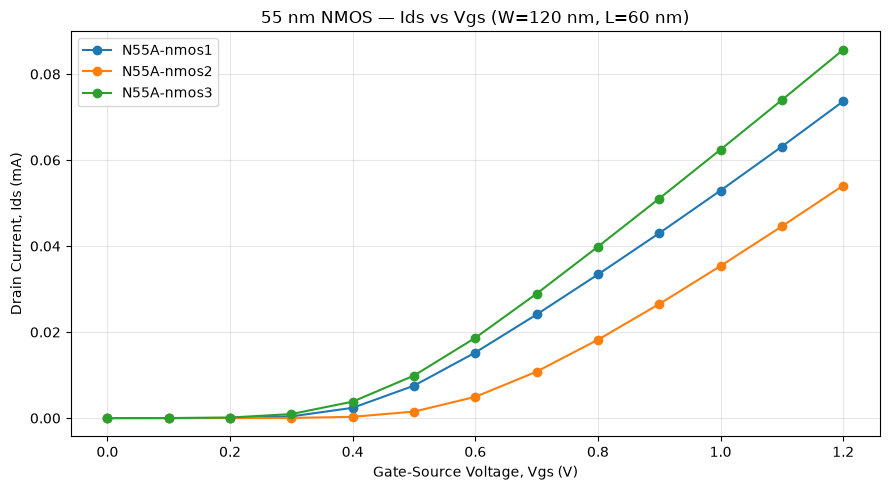

In [16]:
#compare Ids vs Vgs for all three devices
plt.figure(figsize=(9, 5))

for name, df_device in device_dfs.items():

    subset = df_device[
        (df_device["W"] == 120) &
        (df_device["L"] == 60) &
        (df_device["Temp"] == 25) &
        (df_device["Corner"] == "tt") &
        (np.isclose(df_device["Vds"], 1.2))
    ].sort_values("Vgs")

    print(f"{name}: {len(subset)} points")

    plt.plot(
        subset["Vgs"],
        subset["Ids"] * 1e3,
        marker="o",
        label=name
    )

plt.xlabel("Gate-Source Voltage, Vgs (V)")
plt.ylabel("Drain Current, Ids (mA)")
plt.title("55 nm NMOS — Ids vs Vgs (W=120 nm, L=60 nm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Plot: Ids vs Vds

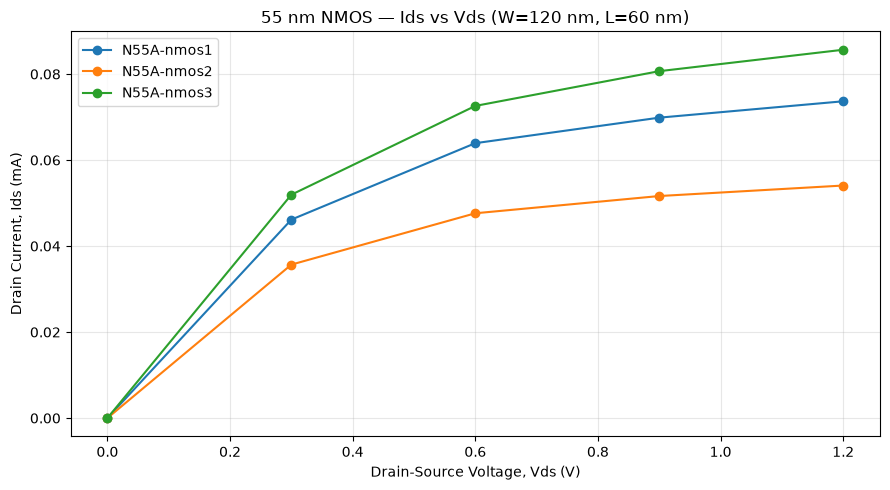

In [17]:
#compare Ids vs Vgs for all three devices
plt.figure(figsize=(9, 5))

for name, df_device in device_dfs.items():

    subset = df_device[
        (df_device["W"] == 120) &
        (df_device["L"] == 60) &
        (df_device["Temp"] == 25) &
        (df_device["Corner"] == "tt") &
        (np.isclose(df_device["Vgs"], 1.2))
    ].sort_values("Vds")

    plt.plot(
        subset["Vds"],
        subset["Ids"] * 1e3,
        marker="o",
        label=name
    )

plt.xlabel("Drain-Source Voltage, Vds (V)")
plt.ylabel("Drain Current, Ids (mA)")
plt.title("55 nm NMOS — Ids vs Vds (W=120 nm, L=60 nm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 2. Preprocessing
The original MESD study uses six operating condition and device geometry features to analyze their importance for drain current. We retain the complete dataset initially and prepare the categorical process corner feature for tree based analysis.

In [18]:
#Prepare first 55 nm NMOS device for reproduction

df_repro = device_dfs["N55A-nmos1"].copy()

features = ["Corner", "Temp", "W", "L", "Vds", "Vgs"]
target = "Ids"

X_repro = pd.get_dummies(
    df_repro[features],
    columns=["Corner"],
    dtype=int
)

y_repro = df_repro[target]

print("Observations:", len(df_repro))
print("Input features:", X_repro.columns.tolist())
print("Target:", target)

assert X_repro.notna().all().all()
assert np.isfinite(y_repro).all()

display(X_repro.head())

Observations: 97500
Input features: ['Temp', 'W', 'L', 'Vds', 'Vgs', 'Corner_ff', 'Corner_ss', 'Corner_tt']
Target: Ids


,Temp,W,L,Vds,Vgs,Corner_ff,Corner_ss,Corner_tt
0,-40,120,60,0.0,0.0,0,0,1
1,-40,120,60,0.0,0.1,0,0,1
2,-40,120,60,0.0,0.2,0,0,1
3,-40,120,60,0.0,0.3,0,0,1
4,-40,120,60,0.0,0.4,0,0,1


## 3. Data Preparation

In [19]:
from sklearn.model_selection import GroupKFold

# Select the primary device
ml_df = device_dfs["N55A-nmos1"].copy()

# Retain positive drain bias and positive currents
ml_df = ml_df.loc[
    (ml_df["Vds"] > 0) &
    (ml_df["Ids"] > 0)
].copy().reset_index(drop=True)

# Logarithmic target and geometry features
ml_df["log10_Ids"] = np.log10(ml_df["Ids"])
ml_df["log_W"] = np.log10(ml_df["W"])
ml_df["log_L"] = np.log10(ml_df["L"])

# Reserve two interior widths for final testing
test_widths = [535, 5033]

train = ml_df.loc[
    ~ml_df["W"].isin(test_widths)
].copy().reset_index(drop=True)

test = ml_df.loc[
    ml_df["W"].isin(test_widths)
].copy().reset_index(drop=True)

# Grouped cross-validation (training data only)
cv = GroupKFold(n_splits=4)
folds = list(cv.split(
    train,
    groups=train["W"]
))

numeric_features = ["Vgs", "Vds", "log_W", "log_L", "Temp"]
features = numeric_features + ["Corner"]

assert set(train["W"]).isdisjoint(set(test["W"]))
assert np.isfinite(ml_df["log10_Ids"]).all()

print("Training observations:", len(train))
print("Test observations:", len(test))
print("Training widths:", sorted(train["W"].unique()))
print("Held-out widths:", sorted(test["W"].unique()))
print("Grouped CV folds:", len(folds))

Training observations: 62400
Test observations: 15600
Training widths: [np.int64(120), np.int64(253), np.int64(1129), np.int64(2384), np.int64(10627), np.int64(22435), np.int64(47366), np.int64(100000)]
Held-out widths: [np.int64(535), np.int64(5033)]
Grouped CV folds: 4


## 4. Model: Linear Regression

Linear Regression is used as the baseline model for predicting logarithmic MOSFET drain current. Model performance is evaluated using width-grouped cross-validation to measure generalization to unseen transistor widths.

Import important libraries

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [21]:
# Use feature lists from data preparation
numeric_features = ["Vgs", "Vds", "log_W", "log_L", "Temp"]
categorical_features = ["Corner"]

def make_linear_model():
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("corner", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ])

    return make_pipeline(
        preprocess,
        LinearRegression()
    )

### Four fold grouped cross-validation

In [ ]:
#here we perform grouped cross-validation for linear regression model and calculate out-of-fold predictions, training RMSE, validation RMSE, validation MAE and median multiplicative error factor
linear_oof = np.full(len(train), np.nan)
linear_train_errors = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    model = make_linear_model()

    X_fit = train.iloc[fit_idx][features]
    y_fit = train.iloc[fit_idx]["log10_Ids"]

    X_val = train.iloc[val_idx][features]
    y_val = train.iloc[val_idx]["log10_Ids"]

    model.fit(X_fit, y_fit)

    train_pred = model.predict(X_fit)
    val_pred = model.predict(X_val)

    linear_train_errors.append(
        np.sqrt(mean_squared_error(y_fit, train_pred))
    )

    linear_oof[val_idx] = val_pred

    print(
        f"Fold {fold_num}: "
        f"Widths = {sorted(train.iloc[val_idx]['W'].unique())}, "
        f"RMSE = {np.sqrt(mean_squared_error(y_val, val_pred)):.5f}"
    )

assert np.isfinite(linear_oof).all()

actual = train["log10_Ids"].to_numpy()

linear_val_rmse = np.sqrt(
    mean_squared_error(actual, linear_oof)
)

linear_val_mae = mean_absolute_error(actual, linear_oof)

linear_median_factor = 10 ** np.median(
    np.abs(actual - linear_oof)
)

print("\nLinear Regression Results")
print(f"Mean training RMSE: {np.mean(linear_train_errors):.5f}")
print(f"Validation RMSE: {linear_val_rmse:.5f}")
print(f"Validation MAE: {linear_val_mae:.5f}")
print(f"Median multiplicative error factor: {linear_median_factor:.5f}")


Fold 1: Widths = [np.int64(2384), np.int64(100000)], RMSE = 0.98352
Fold 2: Widths = [np.int64(1129), np.int64(47366)], RMSE = 0.96395
Fold 3: Widths = [np.int64(253), np.int64(22435)], RMSE = 0.94125
Fold 4: Widths = [np.int64(120), np.int64(10627)], RMSE = 0.96075

Linear Regression Results
Mean training RMSE: 0.95533
Validation RMSE: 0.96248
Validation MAE: 0.80083
Median multiplicative error factor: 5.71661


### Plot: Residuals vs. actual log-current

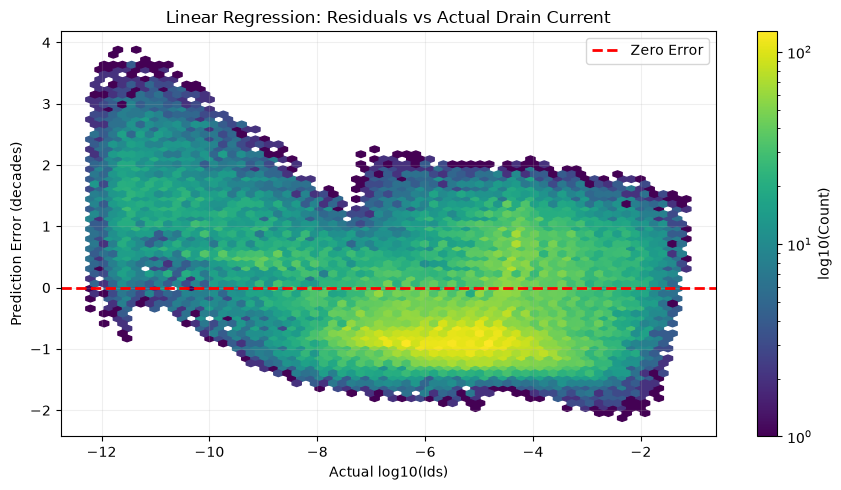

In [ ]:
#Linear Regression residual analysis for out-of-fold predictions

actual = train["log10_Ids"].to_numpy()
residuals = linear_oof - actual

plt.figure(figsize=(9, 5))

plt.hexbin(
    actual,
    residuals,
    gridsize=65,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.xlabel("Actual log10(Ids)")
plt.ylabel("Prediction Error (decades)")
plt.title("Linear Regression: Residuals vs Actual Drain Current")

plt.colorbar(label="log10(Count)")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


### Plot: Per-width validation error

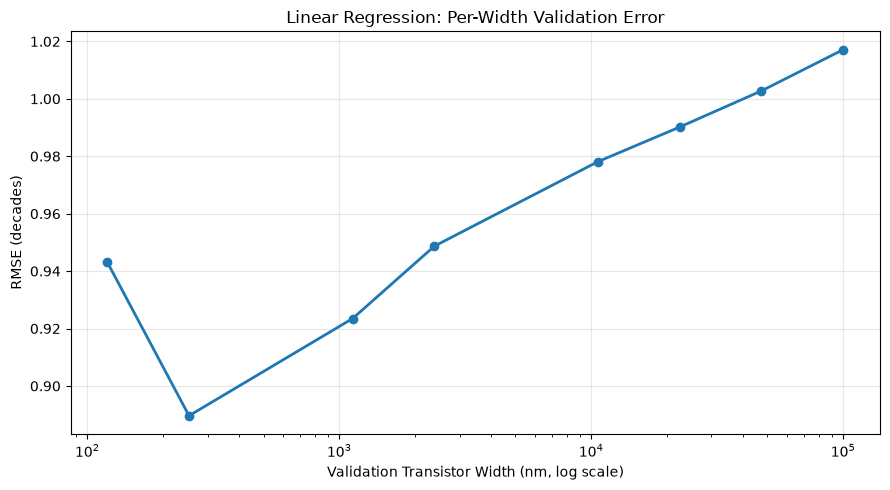

W
120       0.94305
253       0.88963
1129      0.92349
2384      0.94871
10627     0.97812
22435     0.99018
47366     1.00278
100000    1.01713
Name: squared_error, dtype: float64

In [ ]:
#Linear Regression error across unseen transistor widths

linear_per_width = (
    train.assign(
        squared_error=(linear_oof - train["log10_Ids"].to_numpy())**2
    )
    .groupby("W")["squared_error"]
    .mean()
    .pow(0.5)
)

plt.figure(figsize=(9, 5))

plt.plot(
    linear_per_width.index,
    linear_per_width.values,
    marker="o",
    linewidth=2
)

plt.xscale("log")
plt.xlabel("Validation Transistor Width (nm, log scale)")
plt.ylabel("RMSE (decades)")
plt.title("Linear Regression: Per-Width Validation Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(linear_per_width.round(5))


### Plot: Actual vs Predicted plot

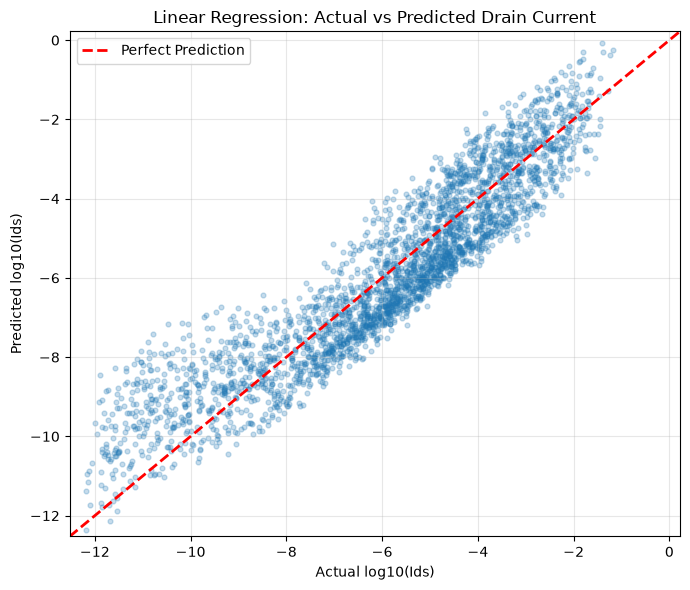

In [ ]:
#Actual vs Predicted Log Current
#Using out-of-fold predictions

actual = train["log10_Ids"].to_numpy()
predicted = linear_oof

rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(actual),
    size=min(3000, len(actual)),
    replace=False
)

plt.figure(figsize=(7, 6))

plt.scatter(
    actual[sample_idx],
    predicted[sample_idx],
    alpha=0.25,
    s=12
)

limits = [
    min(actual.min(), predicted.min()),
    max(actual.max(), predicted.max())
]

plt.plot(
    limits, limits,
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Actual log10(Ids)")
plt.ylabel("Predicted log10(Ids)")
plt.title("Linear Regression: Actual vs Predicted Drain Current")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Observation for Linear Regression: 

The Actual vs Predicted plot shows noticeable deviations from the ideal diagonal particularly at low drain currents. The wide spread of predictions indicates that Linear Regression struggles to capture the nonlinear relationship between MOSFET operating conditions and drain current, confirming the need for more flexible models.

## 5. Model: Polynomial Regression

Polynomial Regression extends the linear model by introducing higher-order terms and interactions between input features. Different polynomial degrees are evaluated to determine whether nonlinear feature expansion improves MOSFET drain current prediction.

In [28]:
from sklearn.preprocessing import PolynomialFeatures

In [29]:
# function to create a polynomial regression model with specified degree
def make_poly(degree):
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("corner", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ), ["Corner"])
    ])

    return make_pipeline(
        preprocess,
        PolynomialFeatures(
            degree=degree,
            include_bias=False
        ),
        StandardScaler(),
        LinearRegression()
    )


### Evaluate polynomial degrees

In [39]:
#here we evaluate polynomial degrees and find validation RMSE and median multiplicative error factor for each degree
poly_results = []
oof_poly = {}

for degree in range(1, 7):
    oof_pred = np.full(len(train), np.nan)
    train_errors = []

    for fit_idx, val_idx in folds:
        model = make_poly(degree)

        X_fit = train.iloc[fit_idx][features]
        y_fit = train.iloc[fit_idx]["log10_Ids"]

        X_val = train.iloc[val_idx][features]

        model.fit(X_fit, y_fit)

        train_errors.append(
            np.sqrt(mean_squared_error(
                y_fit, model.predict(X_fit)
            ))
        )

        oof_pred[val_idx] = model.predict(X_val)

    assert np.isfinite(oof_pred).all()

    actual = train["log10_Ids"].to_numpy()

    val_rmse = np.sqrt(
        mean_squared_error(actual, oof_pred)
    )

    median_factor = 10 ** np.median(
        np.abs(actual - oof_pred)
    )

    oof_poly[degree] = oof_pred

    poly_results.append({
        "degree": degree,
        "train_RMSE": np.mean(train_errors),
        "val_RMSE": val_rmse,
        "median_error_factor": median_factor
    })

    print(
        f"Degree {degree}: "
        f"validation RMSE = {val_rmse:.5f}"
    )

poly_results = pd.DataFrame(poly_results)

display(poly_results.round(5))

Degree 1: validation RMSE = 0.96248
Degree 2: validation RMSE = 0.35663
Degree 3: validation RMSE = 0.25645
Degree 4: validation RMSE = 0.18623
Degree 5: validation RMSE = 0.10548
Degree 6: validation RMSE = 0.06216


,degree,train_RMSE,val_RMSE,median_error_factor
0,1,0.95533,0.96248,5.71661
1,2,0.34835,0.35663,1.62370
2,3,0.25339,0.25645,1.31365
3,4,0.18236,0.18623,1.27013
4,5,0.09916,0.10548,1.14620
5,6,0.05750,0.06216,1.07181


### Per-width validation analysis

In [ ]:
#we do analysis of per width validation error for polynomial regression models of varying degrees
actual = train["log10_Ids"].to_numpy()

poly_per_width = pd.DataFrame({
    f"Degree {degree}": (
        train.assign(
            squared_error=(pred - actual) ** 2
        )
        .groupby("W")["squared_error"]
        .mean()
        .pow(0.5)
    )
    for degree, pred in oof_poly.items()
})

display(poly_per_width.round(5))


,Degree 1,Degree 2,Degree 3,Degree 4,Degree 5,Degree 6
W,,,,,,
120,0.94305,0.37649,0.25162,0.20422,0.13542,0.08112
253,0.88963,0.32977,0.23974,0.18161,0.10242,0.06229
1129,0.92349,0.33952,0.25592,0.18449,0.09962,0.05837
2384,0.94871,0.34797,0.26195,0.18661,0.09989,0.05809
10627,0.97812,0.35370,0.26000,0.18212,0.09710,0.05539
22435,0.99018,0.35662,0.25849,0.18105,0.09721,0.05552
47366,1.00278,0.36136,0.25867,0.18142,0.09841,0.05651
100000,1.01713,0.38445,0.26443,0.18720,0.10826,0.06577


### Plot: Polynomial Regression: Per-Width Validation Error

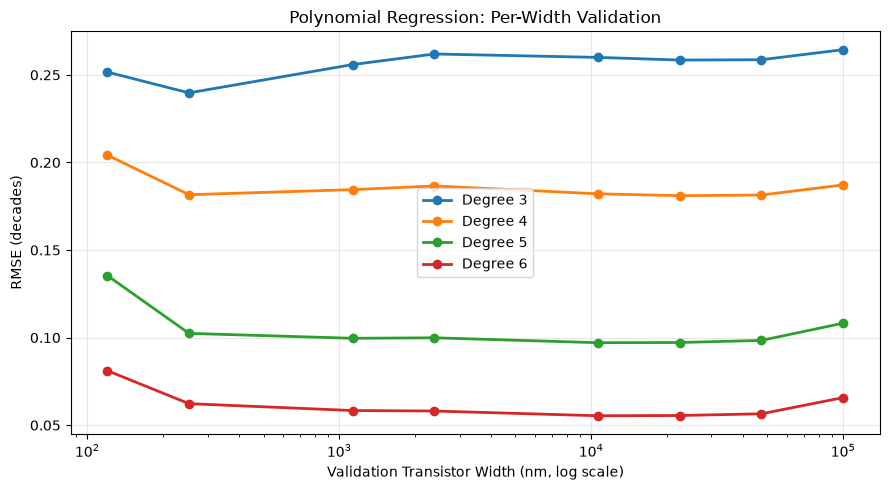

In [32]:
plt.figure(figsize=(9, 5))

for degree in [3, 4, 5, 6]:
    plt.plot(
        poly_per_width.index,
        poly_per_width[f"Degree {degree}"],
        marker="o",
        linewidth=2,
        label=f"Degree {degree}"
    )

plt.xscale("log")
plt.xlabel("Validation Transistor Width (nm, log scale)")
plt.ylabel("RMSE (decades)")
plt.title("Polynomial Regression: Per-Width Validation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Plot: Actual vs Predicted

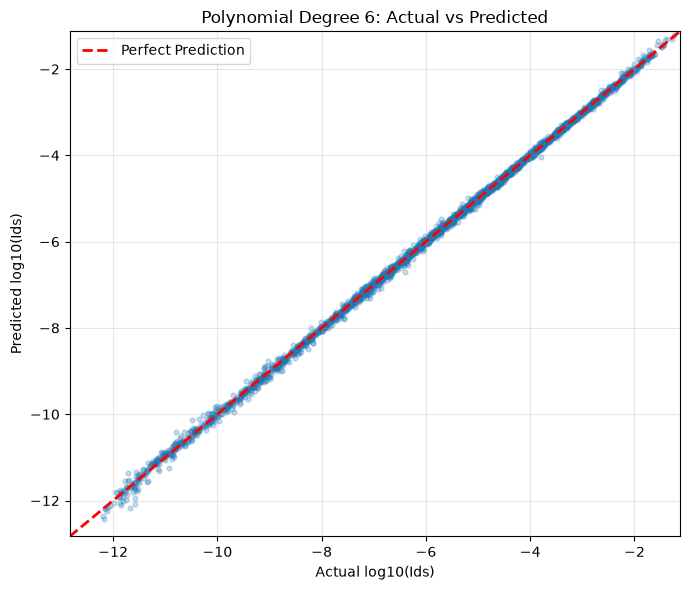

In [38]:
#actual vs predicted log current for degree 6 polynomial regression using out-of-fold predictions

actual = train["log10_Ids"].to_numpy()
predicted = oof_poly[6]

rng = np.random.default_rng(42)
idx = rng.choice(
    len(actual),
    size=min(3000, len(actual)),
    replace=False
)

plt.figure(figsize=(7, 6))

plt.scatter(
    actual[idx],
    predicted[idx],
    alpha=0.25,
    s=12
)

limits = [
    min(actual.min(), predicted.min()),
    max(actual.max(), predicted.max())
]

plt.plot(
    limits,
    limits,
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlim(limits)
plt.ylim(limits)

plt.xlabel("Actual log10(Ids)")
plt.ylabel("Predicted log10(Ids)")
plt.title("Polynomial Degree 6: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Plot: Residual analysis

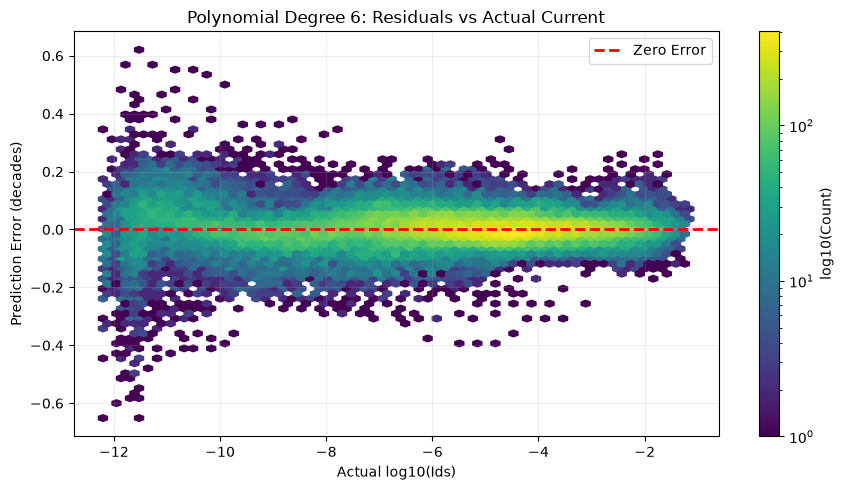

In [36]:
#residual analysis for degree 6 polynomial regression (out-of-fold predictions)
residuals = oof_poly[6] - train["log10_Ids"].to_numpy()

plt.figure(figsize=(9, 5))

plt.hexbin(
    train["log10_Ids"],
    residuals,
    gridsize=65,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.xlabel("Actual log10(Ids)")
plt.ylabel("Prediction Error (decades)")
plt.title("Polynomial Degree 6: Residuals vs Actual Current")

plt.colorbar(label="log10(Count)")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

### Plot: Training and validation RMSE change with polynomial degree

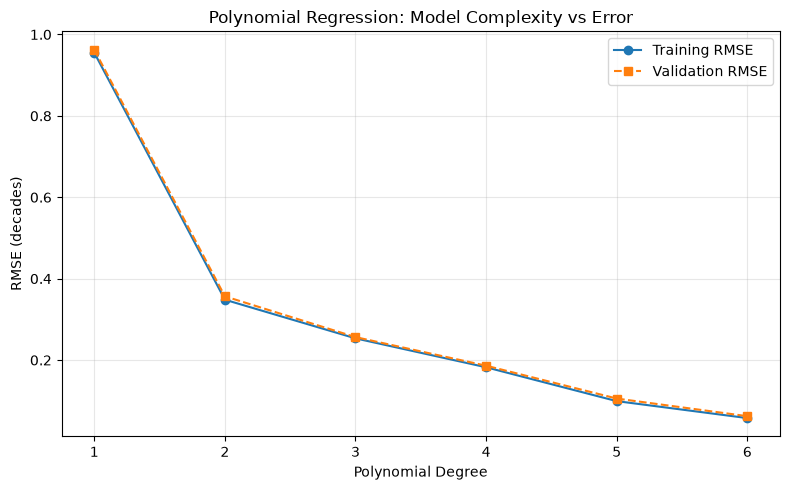

In [37]:
#analysis of polynomial regression model complexity vs error
plt.figure(figsize=(8, 5))

plt.plot(
    poly_results["degree"],
    poly_results["train_RMSE"],
    "o-",
    label="Training RMSE"
)

plt.plot(
    poly_results["degree"],
    poly_results["val_RMSE"],
    "s--",
    label="Validation RMSE"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE (decades)")
plt.title("Polynomial Regression: Model Complexity vs Error")
plt.xticks(poly_results["degree"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Observation of Polynomial Regression

Polynomial Regression significantly improves drain-current prediction compared with Linear Regression. Validation RMSE decreases from 0.96248 to 0.06216 decades as polynomial degree increases from 1 to 6.